# Lab 4: Quantum Communication with Superdense Coding

Welcome to Lab 4! In the previous lab, we explored the fascinating property of entanglement and learned how to create a Bell state, linking two qubits in a special quantum correlation. We saw how their fates are intertwined, but we haven't yet put this powerful resource to work.

Now, we will explore one of the first and most striking applications of entanglement: **superdense coding**. This remarkable quantum protocol allows us to send two classical bits of information (e.g., "00", "01", "10", or "11") by physically transmitting only a *single* qubit. This might sound impossible from a classical perspective, but by leveraging a pre-shared entangled pair, it becomes a reality.

The protocol involves a sender (Alice) and a receiver (Bob). They start by sharing an entangled Bell pair. Alice then performs a specific local operation on *her* qubit to encode the two-bit message she wants to send. She sends only her qubit to Bob. Once Bob has both qubits, he can perform a decoding operation and a measurement to perfectly retrieve Alice's original two-bit message.

In this lab, we will:
*   Implement the full superdense coding protocol, from creating the initial entangled pair to encoding, decoding, and measuring.
*   Define helper functions for each stage of the protocol: creating the Bell pair, encoding Alice's message, and decoding it on Bob's end.
*   Use the **`qasm_simulator`** to send and receive each of the four possible two-bit messages, confirming that the protocol works as expected.
*   Use the **`statevector_simulator`** to investigate the four distinct Bell states that Alice creates to encode her message, providing insight into *how* the information is stored in the entangled system.
*   Demonstrate how a shared entangled resource enables the transmission of two classical bits via one qubit.

Let's dive into the world of quantum communication and see how entanglement can be harnessed as a powerful resource.

In [ ]:
%pip install qiskit qiskit-aer matplotlib

In [ ]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library

In [ ]:
# Define a function that takes a QuantumCircuit (qc)
# and two integers (a & b)
def create_bell_pair(qc, a, b):
    qc.h(a) # Apply a h-gate to the first qubit
    qc.cx(a,b) # Apply a CNOT, using the first qubit as the control

In [ ]:
# Define a function that takes a QuantumCircuit (qc)
# a qubit index (qubit) and a message string (msg)
def encode_message(qc, qubit, msg):
    if msg == "00":
        pass    # To send 00 we do nothing
    elif msg == "10":
        qc.x(qubit) # To send 10 we apply an X-gate
    elif msg == "01":
        qc.z(qubit) # To send 01 we apply a Z-gate
    elif msg == "11":
        qc.z(qubit) # To send 11, we apply a Z-gate
        qc.x(qubit) # followed by an X-gate
    else:
        print("Invalid Message: Sending '00'")

In [ ]:
def decode_message(qc, a, b):
    qc.cx(a,b)
    qc.h(a)

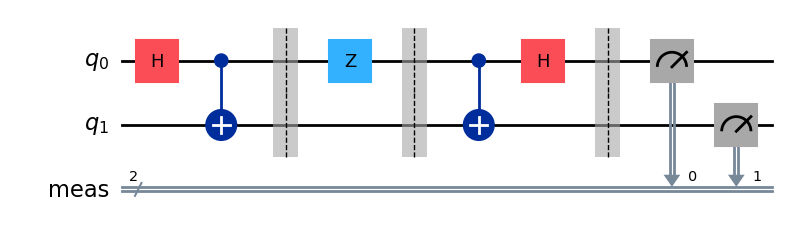

In [ ]:
# Create the quantum circuit with 2 qubits
qc = QuantumCircuit(2)


# First, Charlie creates the entangled pair between Alice and Bob
create_bell_pair(qc, 0, 1)
qc.barrier() # This adds a barrier to our circuit. A barrier
             # separates the gates in our diagram and makes it
             # clear which part of the circuit is which

# At this point, qubit 0 goes to Alice and qubit 1 goes to Bob

# Next, Alice encodes her message onto qubit 0. In this case,
# we want to send the message '10'. You can try changing this
# value and see how it affects the circuit
message = "01"
encode_message(qc, 0, message)
qc.barrier()
# Alice then sends her qubit to Bob.

# After recieving qubit 0, Bob applies the recovery protocol:
decode_message(qc, 0, 1)

# Finally, Bob measures his qubits to read Alice's message
qc.measure_all()

# Draw our output
qc.draw('mpl')

In [ ]:
# Encapsulate the simulation logic into a function
def run_superdense_coding(message_to_send):
    """
    Creates and simulates a superdense coding circuit for a given message.

    Args:
        message_to_send (str): A two-bit string ("00", "01", "10", or "11").

    Returns:
        dict: The measurement counts from the simulation.
    """
    # Create the quantum circuit with 2 qubits and 2 classical bits
    qc = QuantumCircuit(2, 2)

    # 1. Charlie creates the entangled pair
    create_bell_pair(qc, 0, 1)
    qc.barrier()

    # 2. Alice encodes her message
    encode_message(qc, 0, message_to_send)
    qc.barrier()

    # 3. Bob decodes the message
    decode_message(qc, 0, 1)

    # 4. Bob measures the qubits
    # qc.measure_all() # This is fine, but being explicit is good practice
    qc.measure([0, 1], [0, 1])

    # --- Simulation ---
    backend = Aer.get_backend('qasm_simulator')
    job = backend.run(qc, shots=1024)
    result = job.result()
    counts = result.get_counts(qc)

    # Print results for this run
    print(f"--- Results for message '{message_to_send}' ---")
    print("Expected outcome:", message_to_send)
    print("Actual outcome from simulation:", counts)
    plot_histogram(counts, title=f'Result for sending "{message_to_send}"')

    return counts

# --- Run the simulation for all possible messages ---
possible_messages = ["00", "01", "10", "11"]
for msg in possible_messages:
    run_superdense_coding(msg)

# To display all the plots if you are in a script
import matplotlib.pyplot as plt
plt.show()

--- Results for message '00' ---
Expected outcome: 00
Actual outcome from simulation: {'00': 1024}
--- Results for message '01' ---
Expected outcome: 01
Actual outcome from simulation: {'01': 1024}
--- Results for message '10' ---
Expected outcome: 10
Actual outcome from simulation: {'10': 1024}
--- Results for message '11' ---
Expected outcome: 11
Actual outcome from simulation: {'11': 1024}



--- Statevector for message '00' ---


<IPython.core.display.Latex object>

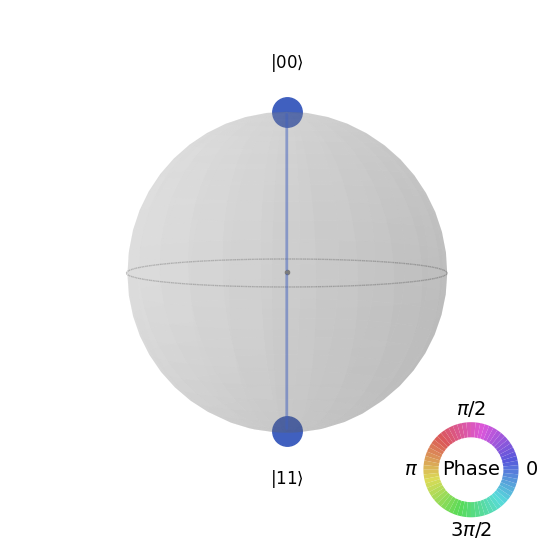


--- Statevector for message '01' ---


<IPython.core.display.Latex object>

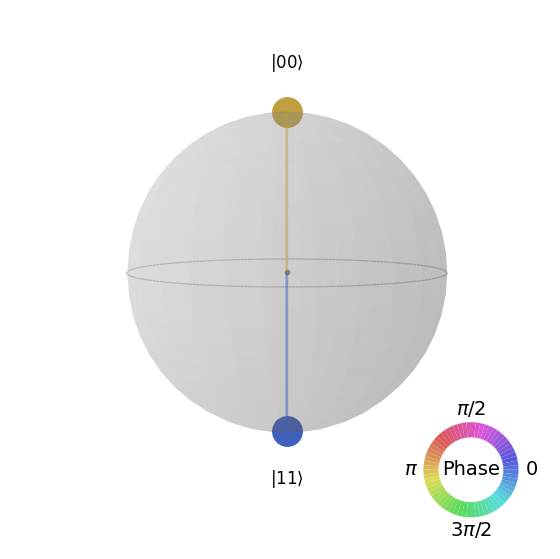


--- Statevector for message '10' ---


<IPython.core.display.Latex object>

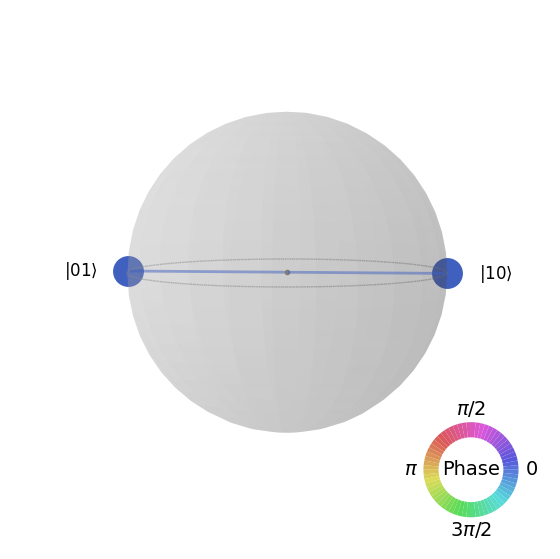


--- Statevector for message '11' ---


<IPython.core.display.Latex object>

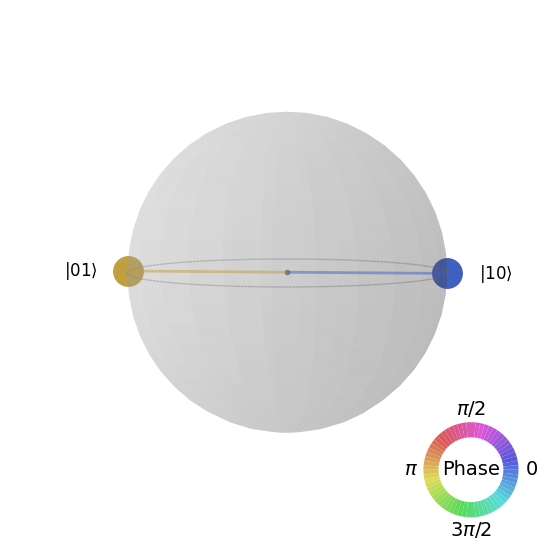

In [ ]:
# Using the statevector simulator to see the states

# The four Bell states correspond to the four messages
# |Φ+⟩ = 1/sqrt(2) * (|00⟩ + |11⟩)  <- Sends "00"
# |Φ-⟩ = 1/sqrt(2) * (|00⟩ - |11⟩)  <- Sends "01" (Z gate)
# |Ψ+⟩ = 1/sqrt(2) * (|01⟩ + |10⟩)  <- Sends "10" (X gate)
# |Ψ-⟩ = 1/sqrt(2) * (|01⟩ - |10⟩)  <- Sends "11" (Z then X gate)

statevec_sim = Aer.get_backend('statevector_simulator')

for message_to_send in ["00", "01", "10", "11"]:
    # Create a circuit for each message, but without measurement
    qc = QuantumCircuit(2)

    # 1. Create Bell pair
    create_bell_pair(qc, 0, 1)

    # 2. Alice encodes
    encode_message(qc, 0, message_to_send)

    # --- Simulate and get the statevector ---
    job = statevec_sim.run(qc)
    result = job.result()
    final_statevector = result.get_statevector()

    print(f"\n--- Statevector for message '{message_to_send}' ---")
    # Using qiskit's array_to_latex for pretty printing
    from qiskit.visualization import array_to_latex
    display(array_to_latex(final_statevector, prefix="\\text{Statevector} = "))

    # Visualize the state using a Q-sphere
    display(plot_state_qsphere(final_statevector))